In [ ]:
# ==========================================================
# IMPORT LIBRARY
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import os
import random
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.backend import clear_session

# ==========================================================
# REPRODUCIBILITY
# ==========================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# ==========================================================
# LOAD DATASET
# ==========================================================

DATA_PATH = "/content/ALL FIX - ALL2.csv"

df = pd.read_csv(DATA_PATH)

# Konversi kolom tanggal
df["Tanggal"] = pd.to_datetime(df["Tanggal"])

# Urutkan data
df = (
    df.sort_values(["Kota", "Tanggal"])
      .reset_index(drop=True)
)

# ==========================================================
# DAFTAR KOTA PENELITIAN
# ==========================================================

CITIES = [
    "DKI JAKARTA",
    "KOTA BANDUNG",
    "KOTA SURABAYA",
    "KOTA MEDAN",
    "KOTA MAKASSAR"
]

print("="*60)
print("Dataset berhasil dimuat")
print("="*60)

print(f"Total Data : {len(df)}")
print(f"Total Kota : {len(CITIES)}")

print("\nDaftar Kota Penelitian:")
for i, city in enumerate(CITIES, start=1):
    total = len(df[df["Kota"] == city])
    print(f"{i}. {city:<20} : {total} data")

display(df.head())

Dataset berhasil dimuat
Total Data : 1560
Total Kota : 5

Daftar Kota Penelitian:
1. DKI JAKARTA          : 312 data
2. KOTA BANDUNG         : 312 data
3. KOTA SURABAYA        : 312 data
4. KOTA MEDAN           : 312 data
5. KOTA MAKASSAR        : 312 data


,Tanggal,Kota,Inflasi,UMR
0,2000-01-01,DKI JAKARTA,1.08,531450
1,2000-02-01,DKI JAKARTA,0.41,531450
2,2000-03-01,DKI JAKARTA,-0.17,531450
3,2000-04-01,DKI JAKARTA,0.11,531450
4,2000-05-01,DKI JAKARTA,1.13,531450


In [ ]:
# ==========================================================
# CELL 3 : DATA SCALING
# ==========================================================

from sklearn.preprocessing import StandardScaler

def scale_data(data):
    """
    Melakukan Z-Score Standardization
    terhadap variabel Inflasi dan UMR.

    Parameters
    ----------
    data : DataFrame

    Returns
    -------
    data_scaled
    scaler_inflasi
    scaler_umr
    """

    scaler_inflasi = StandardScaler()
    scaler_umr = StandardScaler()

    data_scaled = data.copy()

    data_scaled["Inflasi"] = scaler_inflasi.fit_transform(
        data[["Inflasi"]]
    )

    data_scaled["UMR"] = scaler_umr.fit_transform(
        data[["UMR"]]
    )

    return data_scaled, scaler_inflasi, scaler_umr

In [ ]:
# scaler = MinMaxScaler()

# data["Inflasi"] = scaler.fit_transform(
#     data[["Inflasi"]]
# )

In [ ]:
# from sklearn.preprocessing import RobustScaler

# scaler = RobustScaler()

# data["Inflasi"] = scaler.fit_transform(
#     data[["Inflasi"]]
# )

In [ ]:
# ==========================================================
# CELL 4 : MEMBENTUK SEQUENCE (SLIDING WINDOW)
# ==========================================================

def create_sequences(data_scaled, lag, feature_cols=["Inflasi", "UMR"]):
    """
    Membentuk data sequence untuk LSTM.

    Parameters
    ----------
    data_scaled : DataFrame
        Data yang telah dilakukan scaling.

    lag : int
        Jumlah timestep (look back).

    feature_cols : list
        Daftar fitur yang digunakan.

    Returns
    -------
    X : ndarray
        Input LSTM dengan shape:
        (jumlah_sample, lag, jumlah_fitur)

    y : ndarray
        Target Inflasi.
    """

    scaled_values = data_scaled[feature_cols].values
    target_values = data_scaled["Inflasi"].values

    X = []
    y = []

    for i in range(lag, len(data_scaled)):
        X.append(scaled_values[i-lag:i])
        y.append(target_values[i])

    X = np.array(X)
    y = np.array(y)

    return X, y

In [ ]:
# ==========================================================
# CELL 5 : TRAIN-TEST SPLIT
# ==========================================================

def split_data(X, y, train_ratio=0.8):
    """
    Membagi data menjadi Train dan Test secara sekuensial
    (tanpa shuffle) sesuai metodologi time series.

    Parameters
    ----------
    X : ndarray
        Data input sequence.

    y : ndarray
        Data target.

    train_ratio : float
        Proporsi data latih.

    Returns
    -------
    X_train
    X_test
    y_train
    y_test
    """

    train_size = int(len(X) * train_ratio)

    X_train = X[:train_size]
    X_test = X[train_size:]

    y_train = y[:train_size]
    y_test = y[train_size:]

    return X_train, X_test, y_train, y_test

In [ ]:
# ==========================================================
# CELL 7 : MEMBANGUN MODEL STACKED LSTM
# ==========================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def build_model(
    input_shape,
    units=(256, 128, 64),
    learning_rate=0.001
):
    """
    Membangun arsitektur Stacked LSTM
    sesuai artikel Leipary & Setiawan (2025).

    Parameters
    ----------
    input_shape : tuple
        (timesteps, jumlah_fitur)

    units : tuple
        Jumlah unit pada masing-masing layer LSTM.

    learning_rate : float
        Learning Rate optimizer Adam.

    Returns
    -------
    model
    """

    model = Sequential([

        Input(shape=input_shape),

        # LSTM Layer 1
        LSTM(
            units=units[0],
            return_sequences=True
        ),
        Dropout(0.1),

        # LSTM Layer 2
        LSTM(
            units=units[1],
            return_sequences=True
        ),
        Dropout(0.1),

        # LSTM Layer 3
        LSTM(
            units=units[2],
            return_sequences=False
        ),
        Dropout(0.1),

        # Output Layer
        Dense(1)

    ])

    model.compile(

        optimizer=Adam(
            learning_rate=learning_rate
        ),

        loss="mean_squared_error",

        metrics=["mae"]

    )

    return model

In [ ]:
# ==========================================================
# CELL 8 : TRAINING MODEL
# ==========================================================

def train_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    epochs=100,
    batch_size=32
):
    """
    Melatih model Stacked LSTM.

    Parameters
    ----------
    model : keras.Model

    X_train, y_train

    X_test, y_test

    epochs : int

    batch_size : int

    Returns
    -------
    history
    """

    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_test, y_test),

        epochs=epochs,

        batch_size=batch_size,

        shuffle=False,

        verbose=1

    )

    return history

In [ ]:
# ==========================================================
# CELL 9 : PREDIKSI & INVERSE TRANSFORM
# ==========================================================

def predict_model(model, X_test, y_test, scaler_inflasi):
    """
    Melakukan prediksi dan mengembalikan hasil ke skala asli.

    Parameters
    ----------
    model : keras.Model

    X_test : ndarray

    y_test : ndarray

    scaler_inflasi : StandardScaler

    Returns
    -------
    y_test_actual
    y_pred_actual
    """

    # Prediksi
    y_pred = model.predict(X_test, verbose=0)

    # Inverse transform
    y_pred_actual = scaler_inflasi.inverse_transform(y_pred)

    y_test_actual = scaler_inflasi.inverse_transform(
        y_test.reshape(-1, 1)
    )

    return y_test_actual, y_pred_actual

In [ ]:
# ==========================================================
# CELL 10 : EVALUASI MODEL
# ==========================================================

def evaluate_model(y_test_actual, y_pred_actual):
    """
    Menghitung metrik evaluasi model pada skala asli.

    Parameters
    ----------
    y_test_actual : ndarray

    y_pred_actual : ndarray

    Returns
    -------
    metrics : dict
    """

    # ===============================
    # Mean Squared Error
    # ===============================
    mse = mean_squared_error(
        y_test_actual,
        y_pred_actual
    )

    # ===============================
    # Root Mean Squared Error
    # ===============================
    rmse = np.sqrt(mse)

    # ===============================
    # Mean Absolute Error
    # ===============================
    mae = mean_absolute_error(
        y_test_actual,
        y_pred_actual
    )

    # ===============================
    # Symmetric Mean Absolute Percentage Error
    # ===============================
    denominator = np.abs(y_test_actual) + np.abs(y_pred_actual)

    smape = np.mean(
        np.where(
            denominator == 0,
            0,
            2 * np.abs(y_pred_actual - y_test_actual) / denominator
        )
    )

    smape_percent = smape * 100

    metrics = {

        "MSE": mse,

        "RMSE": rmse,

        "MAE": mae,

        "sMAPE": smape,

        "sMAPE (%)": smape_percent

    }

    return metrics

In [ ]:
# ==========================================================
# EXPERIMENT A : PARAMETER LAG
# ==========================================================

LAG_GRID = [3, 6, 9, 12]

experiment_A = []

In [ ]:
# ==========================================================
# EXPERIMENT A : LOOP SELURUH KOTA
# ==========================================================

for city in CITIES:

    print("="*70)
    print(city)
    print("="*70)

    city_data = df[df["Kota"] == city].copy()

    city_data, scaler_inflasi, scaler_umr = scale_data(city_data)

    for lag in LAG_GRID:

        print(f"\nLag = {lag}")

        clear_session()

        X, y = create_sequences(
            city_data,
            lag=lag
        )

        X_train, X_test, y_train, y_test = split_data(X, y)

        model = build_model(
            input_shape=(X_train.shape[1], X_train.shape[2])
        )

        history = train_model(
            model,
            X_train,
            y_train,
            X_test,
            y_test,
            epochs=100,
            batch_size=32
        )

        y_actual, y_pred = predict_model(
            model,
            X_test,
            y_test,
            scaler_inflasi
        )

        metrics = evaluate_model(
            y_actual,
            y_pred
        )

        experiment_A.append({

            "City": city,
            "Lag": lag,

            **metrics

        })

DKI JAKARTA

Lag = 3
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - loss: 1.1094 - mae: 0.6093 - val_loss: 0.4964 - val_mae: 0.4902
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0675 - mae: 0.6043 - val_loss: 0.4321 - val_mae: 0.4231
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0529 - mae: 0.6060 - val_loss: 0.4304 - val_mae: 0.4041
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0432 - mae: 0.5951 - val_loss: 0.4462 - val_mae: 0.4145
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0389 - mae: 0.5832 - val_loss: 0.4660 - val_mae: 0.4244
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0399 - mae: 0.5826 - val_loss: 0.4678 - val_mae: 0.4269
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0424 - mae: 0.5835 - val_loss: 0.4546 - val_mae: 0.4237
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.0370 - mae: 0.5810 - val_loss: 0.4467 - val_mae: 0.4221
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step -


Lag = 12
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - loss: 1.1199 - mae: 0.6202 - val_loss: 0.4426 - val_mae: 0.4349
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.0568 - mae: 0.5738 - val_loss: 0.4565 - val_mae: 0.4184
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 1.0504 - mae: 0.5811 - val_loss: 0.5563 - val_mae: 0.4765
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.0529 - mae: 0.5791 - val_loss: 0.4584 - val_mae: 0.4174
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.0457 - mae: 0.5680 - val_loss: 0.4726 - val_mae: 0.4223
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 1.0372 - mae: 0.5738 - val_loss: 0.4912 - val_mae: 0.4305
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 1.0284 - mae: 0.5709 - val_loss: 0.4628 - val_mae: 0.4148
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 1.0313 - mae: 0.5606 - val_loss: 0.4896 - val_mae: 0.4305
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 1.01

In [ ]:
# ==========================================================
# HASIL EXPERIMENT A
# ==========================================================

result_A = pd.DataFrame(experiment_A)

display(result_A)

result_A.to_csv(
    "experiment_A_lag.csv",
    index=False
)

,City,Lag,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,0.183417,0.428272,0.272227,1.076066,107.606636
1,DKI JAKARTA,6,0.196436,0.443211,0.265855,1.142348,114.234844
2,DKI JAKARTA,9,0.190272,0.436202,0.268854,1.067625,106.762505
3,DKI JAKARTA,12,0.192128,0.438324,0.272954,1.070157,107.015651
4,KOTA BANDUNG,3,0.281621,0.530679,0.331376,1.108176,110.817597
5,KOTA BANDUNG,6,0.291551,0.539955,0.350955,1.088866,108.886629
6,KOTA BANDUNG,9,0.315240,0.561463,0.349891,1.188345,118.834528
7,KOTA BANDUNG,12,0.334922,0.578724,0.391836,1.487132,148.713159
8,KOTA SURABAYA,3,0.208975,0.457138,0.356776,1.706205,170.620531
9,KOTA SURABAYA,6,0.160219,0.400274,0.290428,1.013388,101.338787


In [ ]:
# ==========================================================
# BEST LAG SETIAP KOTA
# ==========================================================

best_lag = (
    result_A
    .sort_values("RMSE")
    .groupby("City")
    .first()
    .reset_index()
)

display(best_lag)

,City,Lag,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,0.183417,0.428272,0.272227,1.076066,107.606636
1,KOTA BANDUNG,3,0.281621,0.530679,0.331376,1.108176,110.817597
2,KOTA MAKASSAR,3,0.281352,0.530427,0.372564,1.266730,126.673035
3,KOTA MEDAN,3,0.334102,0.578016,0.451844,1.313249,131.324906
4,KOTA SURABAYA,6,0.160219,0.400274,0.290428,1.013388,101.338787


In [ ]:
# ==========================================================
# EXPERIMENT B : OPTIMASI JUMLAH UNITS LSTM
# ==========================================================

UNITS_GRID = [

    (64, 32, 16),

    (128, 64, 32),

    (256, 128, 64),

    (512, 256, 128)

]

experiment_B = []

In [ ]:
# ==========================================================
# MENGAMBIL BEST LAG DARI EXPERIMENT A
# ==========================================================

best_lag_dict = dict(zip(best_lag["City"], best_lag["Lag"]))

best_lag_dict

{'DKI JAKARTA': 3,
 'KOTA BANDUNG': 3,
 'KOTA MAKASSAR': 3,
 'KOTA MEDAN': 3,
 'KOTA SURABAYA': 6}

In [ ]:
# ==========================================================
# EXPERIMENT B : LOOP OPTIMASI UNITS
# ==========================================================

for city in CITIES:

    print("="*70)
    print(f"KOTA : {city}")
    print("="*70)

    # -----------------------------
    # Ambil data kota
    # -----------------------------
    city_data = df[df["Kota"] == city].copy()

    # -----------------------------
    # Scaling
    # -----------------------------
    city_data, scaler_inflasi, scaler_umr = scale_data(city_data)

    # -----------------------------
    # Gunakan Best Lag hasil Exp A
    # -----------------------------
    lag = best_lag_dict[city]

    print(f"Best Lag : {lag}")

    # -----------------------------
    # Membuat sequence
    # -----------------------------
    X, y = create_sequences(
        city_data,
        lag=lag
    )

    X_train, X_test, y_train, y_test = split_data(X, y)

    # =====================================================
    # Loop seluruh kombinasi Units
    # =====================================================

    for units in UNITS_GRID:

        print(f"\nUnits : {units}")

        clear_session()

        model = build_model(

            input_shape=(X_train.shape[1], X_train.shape[2]),

            units=units

        )

        history = train_model(

            model,

            X_train,
            y_train,

            X_test,
            y_test,

            epochs=100,

            batch_size=32

        )

        y_actual, y_pred = predict_model(

            model,

            X_test,

            y_test,

            scaler_inflasi

        )

        metrics = evaluate_model(

            y_actual,

            y_pred

        )

        experiment_B.append({

            "City": city,

            "Lag": lag,

            "Units": str(units),

            **metrics

        })

        print(
            f"RMSE = {metrics['RMSE']:.4f} | "
            f"MAE = {metrics['MAE']:.4f}"
        )

KOTA : DKI JAKARTA
Best Lag : 3

Units : (64, 32, 16)
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - loss: 1.1154 - mae: 0.6085 - val_loss: 0.5548 - val_mae: 0.5528
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1.1045 - mae: 0.6075 - val_loss: 0.5428 - val_mae: 0.5412
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 1.0981 - mae: 0.6069 - val_loss: 0.5262 - val_mae: 0.5251
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 1.0858 - mae: 0.6068 - val_loss: 0.5049 - val_mae: 0.5029
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 1.0724 - mae: 0.6039 - val_loss: 0.4803 - val_mae: 0.4779
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 1.0651 - mae: 0.6077 - val_loss: 0.4565 - val_mae: 0.4544
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1.0569 - mae: 0.6068 - val_loss: 0.4373 - val_mae: 0.4346
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 1.0470 - mae: 0.6035 - val_loss: 0.4245 - val_mae: 0.4215
Epoch 9/100
8/8 ━━

In [ ]:
# ==========================================================
# HASIL EXPERIMENT B
# ==========================================================

result_B = pd.DataFrame(experiment_B)

display(result_B)

result_B.to_csv(
    "experiment_B_units.csv",
    index=False
)

,City,Lag,Units,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(64, 32, 16)",0.178889,0.422953,0.273378,1.148556,114.855582
1,DKI JAKARTA,3,"(128, 64, 32)",0.174840,0.418139,0.266336,1.142433,114.243284
2,DKI JAKARTA,3,"(256, 128, 64)",0.180773,0.425174,0.267267,1.105057,110.505685
3,DKI JAKARTA,3,"(512, 256, 128)",0.181784,0.426362,0.270918,1.068135,106.813489
4,KOTA BANDUNG,3,"(64, 32, 16)",0.270424,0.520023,0.328983,1.066941,106.694136
5,KOTA BANDUNG,3,"(128, 64, 32)",0.271234,0.520802,0.331377,1.096927,109.692671
6,KOTA BANDUNG,3,"(256, 128, 64)",0.269373,0.519012,0.325316,1.032657,103.265736
7,KOTA BANDUNG,3,"(512, 256, 128)",0.335231,0.578991,0.356282,1.131108,113.110843
8,KOTA SURABAYA,6,"(64, 32, 16)",0.250076,0.500076,0.395108,1.709682,170.968236
9,KOTA SURABAYA,6,"(128, 64, 32)",0.212553,0.461035,0.352112,1.511157,151.115740


In [ ]:
# ==========================================================
# BEST UNITS SETIAP KOTA
# ==========================================================

best_units = (

    result_B

    .sort_values("RMSE")

    .groupby("City")

    .first()

    .reset_index()

)

display(best_units)

,City,Lag,Units,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.174840,0.418139,0.266336,1.142433,114.243284
1,KOTA BANDUNG,3,"(256, 128, 64)",0.269373,0.519012,0.325316,1.032657,103.265736
2,KOTA MAKASSAR,3,"(256, 128, 64)",0.288196,0.536839,0.374489,1.318039,131.803940
3,KOTA MEDAN,3,"(64, 32, 16)",0.295688,0.543772,0.424477,1.368776,136.877577
4,KOTA SURABAYA,6,"(512, 256, 128)",0.192843,0.439139,0.342805,1.573369,157.336875


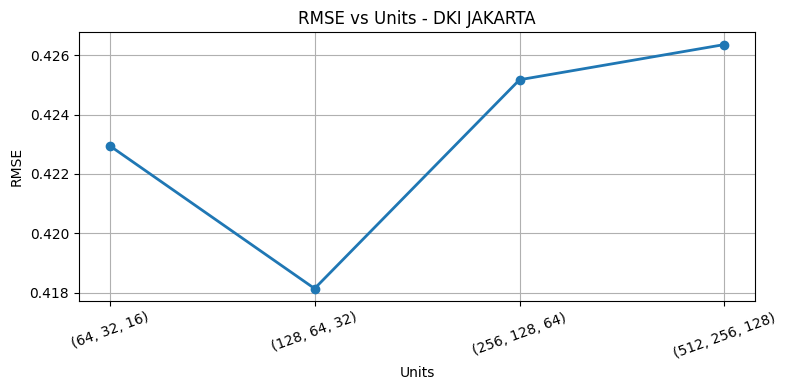

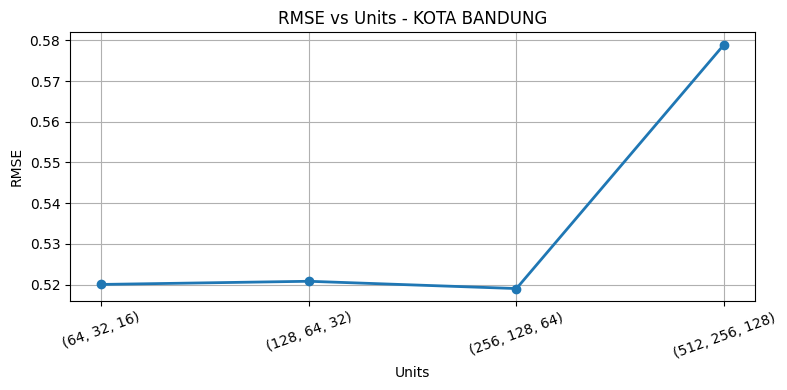

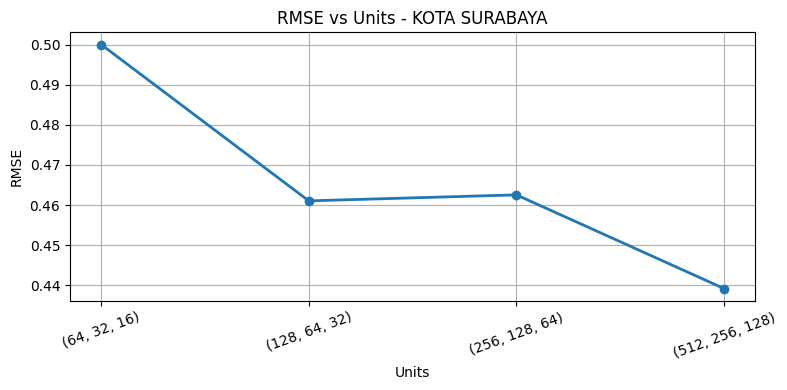

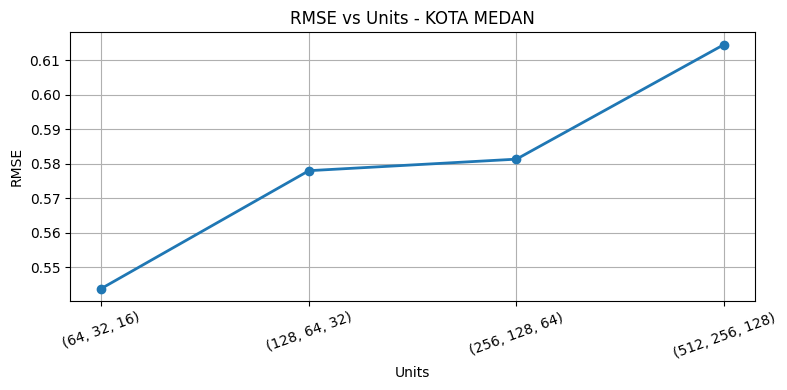

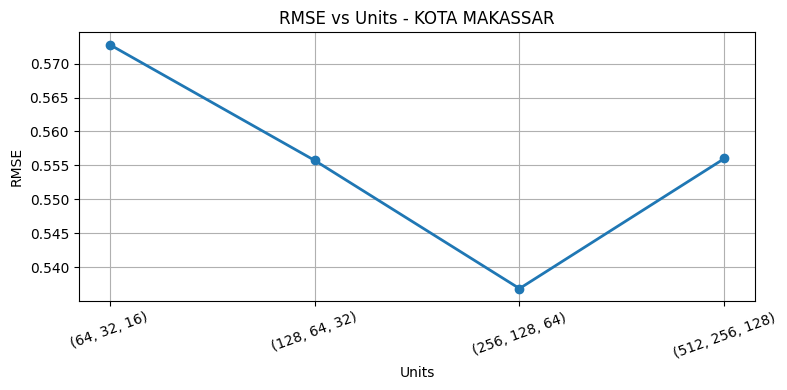

In [ ]:
# ==========================================================
# VISUALISASI RMSE SETIAP KOMBINASI UNITS
# ==========================================================

for city in CITIES:

    plt.figure(figsize=(8,4))

    temp = result_B[result_B["City"] == city]

    plt.plot(
        temp["Units"],
        temp["RMSE"],
        marker="o",
        linewidth=2
    )

    plt.title(f"RMSE vs Units - {city}")

    plt.xlabel("Units")

    plt.ylabel("RMSE")

    plt.grid(True)

    plt.xticks(rotation=20)

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# EXPERIMENT C : OPTIMASI LEARNING RATE
# ==========================================================

LR_GRID = [

    0.01,

    0.001,

    0.0001

]

experiment_C = []

In [ ]:
# ==========================================================
# MENGAMBIL BEST UNITS DARI EXPERIMENT B
# ==========================================================

import ast

best_units_dict = {}

for _, row in best_units.iterrows():

    best_units_dict[row["City"]] = ast.literal_eval(row["Units"])

best_units_dict

{'DKI JAKARTA': (128, 64, 32),
 'KOTA BANDUNG': (256, 128, 64),
 'KOTA MAKASSAR': (256, 128, 64),
 'KOTA MEDAN': (64, 32, 16),
 'KOTA SURABAYA': (512, 256, 128)}

In [ ]:
# ==========================================================
# EXPERIMENT C : LOOP OPTIMASI LEARNING RATE
# ==========================================================

for city in CITIES:

    print("="*70)
    print(f"KOTA : {city}")
    print("="*70)

    # -----------------------------
    # Ambil Data
    # -----------------------------
    city_data = df[df["Kota"] == city].copy()

    # -----------------------------
    # Scaling
    # -----------------------------
    city_data, scaler_inflasi, scaler_umr = scale_data(city_data)

    # -----------------------------
    # Best Lag
    # -----------------------------
    lag = best_lag_dict[city]

    # -----------------------------
    # Best Units
    # -----------------------------
    units = best_units_dict[city]

    print(f"Best Lag   : {lag}")
    print(f"Best Units : {units}")

    # -----------------------------
    # Sequence
    # -----------------------------
    X, y = create_sequences(
        city_data,
        lag=lag
    )

    X_train, X_test, y_train, y_test = split_data(X, y)

    # =====================================================
    # Loop Learning Rate
    # =====================================================

    for lr in LR_GRID:

        print(f"\nLearning Rate : {lr}")

        clear_session()

        model = build_model(

            input_shape=(X_train.shape[1], X_train.shape[2]),

            units=units,

            learning_rate=lr

        )

        history = train_model(

            model,

            X_train,
            y_train,

            X_test,
            y_test,

            epochs=100,

            batch_size=32

        )

        y_actual, y_pred = predict_model(

            model,

            X_test,

            y_test,

            scaler_inflasi

        )

        metrics = evaluate_model(

            y_actual,

            y_pred

        )

        experiment_C.append({

            "City": city,

            "Lag": lag,

            "Units": str(units),

            "Learning Rate": lr,

            **metrics

        })

        print(
            f"RMSE = {metrics['RMSE']:.4f} | "
            f"MAE = {metrics['MAE']:.4f}"
        )

KOTA : DKI JAKARTA
Best Lag   : 3
Best Units : (128, 64, 32)

Learning Rate : 0.01
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - loss: 1.1291 - mae: 0.6502 - val_loss: 0.5241 - val_mae: 0.5218
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.0844 - mae: 0.5868 - val_loss: 0.5127 - val_mae: 0.4502
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0848 - mae: 0.6040 - val_loss: 0.4303 - val_mae: 0.4476
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.1165 - mae: 0.6624 - val_loss: 0.6438 - val_mae: 0.6347
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0798 - mae: 0.6133 - val_loss: 0.5011 - val_mae: 0.4910
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0577 - mae: 0.5920 - val_loss: 0.4424 - val_mae: 0.4120
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 1.0267 - mae: 0.5795 - val_loss: 0.5391 - val_mae: 0.4779
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 1.0933 - mae: 0.5956 - val_loss: 0.5323 - val_m

In [ ]:
# ==========================================================
# HASIL EXPERIMENT C
# ==========================================================

result_C = pd.DataFrame(experiment_C)

display(result_C)

result_C.to_csv(
    "experiment_C_learning_rate.csv",
    index=False
)

,City,Lag,Units,Learning Rate,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.0100,0.184528,0.429567,0.273720,1.153987,115.398663
1,DKI JAKARTA,3,"(128, 64, 32)",0.0010,0.186103,0.431396,0.267298,1.117577,111.757731
2,DKI JAKARTA,3,"(128, 64, 32)",0.0001,0.192962,0.439274,0.278104,1.275521,127.552138
3,KOTA BANDUNG,3,"(256, 128, 64)",0.0100,0.266333,0.516075,0.324033,1.080337,108.033709
4,KOTA BANDUNG,3,"(256, 128, 64)",0.0010,0.286637,0.535385,0.337410,1.062253,106.225262
5,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,0.259113,0.509032,0.320804,1.076497,107.649705
6,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,0.158156,0.397688,0.290582,0.944517,94.451690
7,KOTA SURABAYA,6,"(512, 256, 128)",0.0010,0.209258,0.457447,0.355737,1.593086,159.308649
8,KOTA SURABAYA,6,"(512, 256, 128)",0.0001,0.176270,0.419846,0.312885,1.241790,124.178992
9,KOTA MEDAN,3,"(64, 32, 16)",0.0100,0.650709,0.806666,0.632430,1.405171,140.517099


In [ ]:
# ==========================================================
# BEST LEARNING RATE SETIAP KOTA
# ==========================================================

best_lr = (

    result_C

    .sort_values("RMSE")

    .groupby("City")

    .first()

    .reset_index()

)

display(best_lr)

,City,Lag,Units,Learning Rate,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.0100,0.184528,0.429567,0.273720,1.153987,115.398663
1,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,0.259113,0.509032,0.320804,1.076497,107.649705
2,KOTA MAKASSAR,3,"(256, 128, 64)",0.0010,0.288275,0.536913,0.370150,1.290401,129.040104
3,KOTA MEDAN,3,"(64, 32, 16)",0.0010,0.296769,0.544765,0.426489,1.388930,138.893032
4,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,0.158156,0.397688,0.290582,0.944517,94.451690


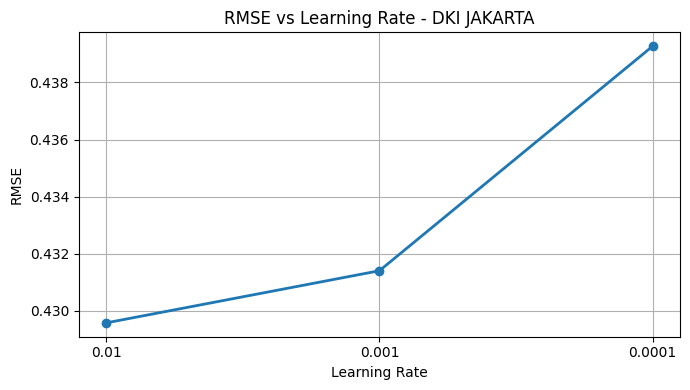

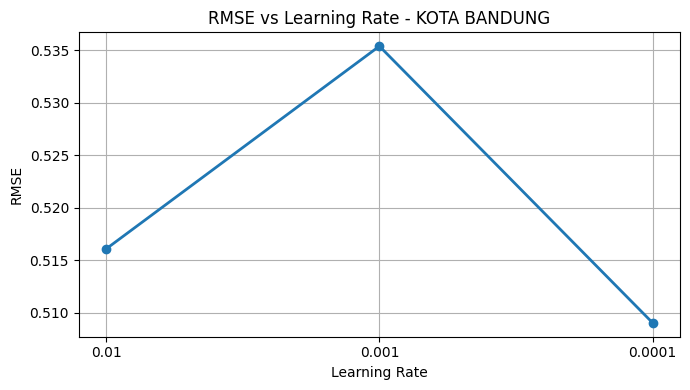

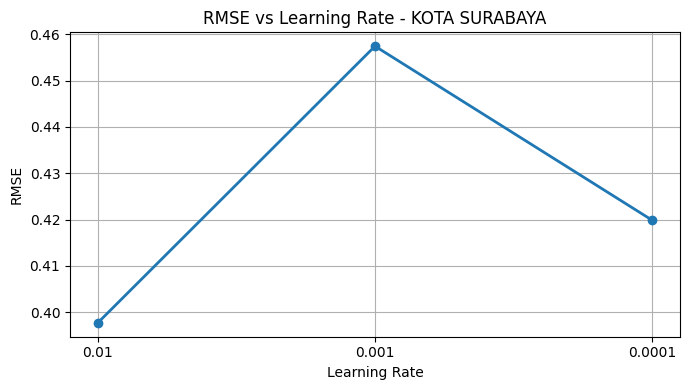

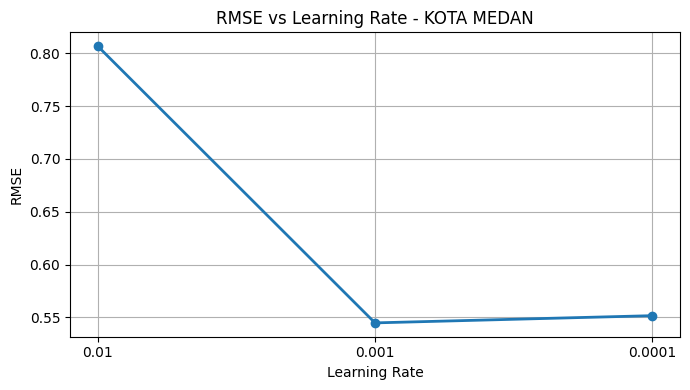

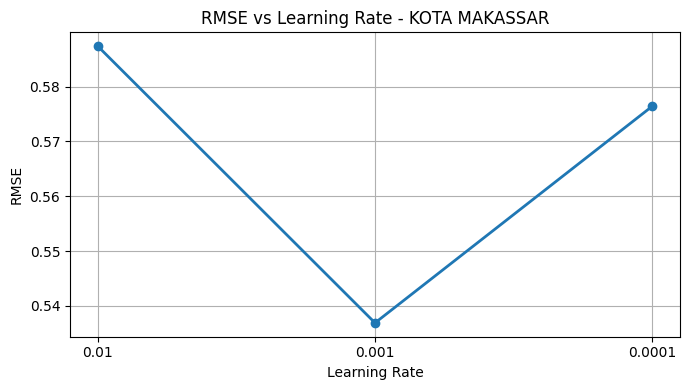

In [ ]:
# ==========================================================
# VISUALISASI RMSE SETIAP LEARNING RATE
# ==========================================================

for city in CITIES:

    plt.figure(figsize=(7,4))

    temp = result_C[result_C["City"] == city]

    plt.plot(
        temp["Learning Rate"].astype(str),
        temp["RMSE"],
        marker="o",
        linewidth=2
    )

    plt.title(f"RMSE vs Learning Rate - {city}")

    plt.xlabel("Learning Rate")

    plt.ylabel("RMSE")

    plt.grid(True)

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# EXPERIMENT D : OPTIMASI EPOCH
# ==========================================================

EPOCH_GRID = [

    50,

    100,

    150,

    200

]

experiment_D = []

In [ ]:
# ==========================================================
# MENGAMBIL BEST LEARNING RATE DARI EXPERIMENT C
# ==========================================================

best_lr_dict = dict(zip(
    best_lr["City"],
    best_lr["Learning Rate"]
))

best_lr_dict

{'DKI JAKARTA': 0.01,
 'KOTA BANDUNG': 0.0001,
 'KOTA MAKASSAR': 0.001,
 'KOTA MEDAN': 0.001,
 'KOTA SURABAYA': 0.01}

In [ ]:
# ==========================================================
# EXPERIMENT D : LOOP OPTIMASI EPOCH
# ==========================================================

for city in CITIES:

    print("="*70)
    print(f"KOTA : {city}")
    print("="*70)

    # -----------------------------
    # Ambil data kota
    # -----------------------------
    city_data = df[df["Kota"] == city].copy()

    # -----------------------------
    # Scaling
    # -----------------------------
    city_data, scaler_inflasi, scaler_umr = scale_data(city_data)

    # -----------------------------
    # Hyperparameter terbaik
    # -----------------------------
    lag = best_lag_dict[city]
    units = best_units_dict[city]
    lr = best_lr_dict[city]

    print(f"Best Lag           : {lag}")
    print(f"Best Units         : {units}")
    print(f"Best Learning Rate : {lr}")

    # -----------------------------
    # Membuat sequence
    # -----------------------------
    X, y = create_sequences(
        city_data,
        lag=lag
    )

    X_train, X_test, y_train, y_test = split_data(X, y)

    # =====================================================
    # Loop Epoch
    # =====================================================

    for epoch in EPOCH_GRID:

        print(f"\nEpoch : {epoch}")

        clear_session()

        model = build_model(

            input_shape=(X_train.shape[1], X_train.shape[2]),

            units=units,

            learning_rate=lr

        )

        history = train_model(

            model,

            X_train,
            y_train,

            X_test,
            y_test,

            epochs=epoch,

            batch_size=32

        )

        y_actual, y_pred = predict_model(

            model,

            X_test,

            y_test,

            scaler_inflasi

        )

        metrics = evaluate_model(

            y_actual,

            y_pred

        )

        experiment_D.append({

            "City": city,

            "Lag": lag,

            "Units": str(units),

            "Learning Rate": lr,

            "Epoch": epoch,

            **metrics

        })

        print(
            f"RMSE = {metrics['RMSE']:.4f} | "
            f"MAE = {metrics['MAE']:.4f}"
        )

Streaming output truncated to the last 5000 lines.
Epoch 42/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.6309 - mae: 0.4902 - val_loss: 0.4225 - val_mae: 0.4146
Epoch 43/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5965 - mae: 0.4830 - val_loss: 0.4483 - val_mae: 0.4340
Epoch 44/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.8466 - mae: 0.4971 - val_loss: 0.4125 - val_mae: 0.4181
Epoch 45/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.7917 - mae: 0.4852 - val_loss: 0.4540 - val_mae: 0.4373
Epoch 46/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.7603 - mae: 0.5298 - val_loss: 0.4470 - val_mae: 0.4459
Epoch 47/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.7156 - mae: 0.5038 - val_loss: 0.4338 - val_mae: 0.4254
Epoch 48/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.7067 - mae: 0.5207 - val_loss: 0.4303 - val_mae: 0.4232
Epoch 49/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5467 - mae: 0.4816 - val_loss: 0.4189 - val_mae: 0.4220
Epoch 50/50
8/8 ━━━━━

In [ ]:
# ==========================================================
# HASIL EXPERIMENT D
# ==========================================================

result_D = pd.DataFrame(experiment_D)

display(result_D)

result_D.to_csv(
    "experiment_D_epoch.csv",
    index=False
)

,City,Lag,Units,Learning Rate,Epoch,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,0.189189,0.434958,0.277931,1.128416,112.841575
1,DKI JAKARTA,3,"(128, 64, 32)",0.0100,100,0.211389,0.459770,0.278582,1.142579,114.257899
2,DKI JAKARTA,3,"(128, 64, 32)",0.0100,150,0.263458,0.513281,0.312607,1.322787,132.278738
3,DKI JAKARTA,3,"(128, 64, 32)",0.0100,200,0.240181,0.490083,0.327924,1.454699,145.469902
4,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,50,0.267111,0.516828,0.325168,1.166748,116.674795
5,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,100,0.258934,0.508856,0.319989,1.075368,107.536826
6,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,0.255406,0.505377,0.318266,1.041328,104.132786
7,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,200,0.262288,0.512141,0.327147,1.094525,109.452511
8,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,50,0.183004,0.427790,0.320447,1.299397,129.939698
9,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,100,0.160239,0.400299,0.305800,0.940095,94.009519


In [ ]:
# ==========================================================
# BEST EPOCH SETIAP KOTA
# ==========================================================

best_epoch = (

    result_D

    .sort_values("RMSE")

    .groupby("City")

    .first()

    .reset_index()

)

display(best_epoch)

,City,Lag,Units,Learning Rate,Epoch,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,0.189189,0.434958,0.277931,1.128416,112.841575
1,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,0.255406,0.505377,0.318266,1.041328,104.132786
2,KOTA MAKASSAR,3,"(256, 128, 64)",0.0010,100,0.282607,0.531608,0.371634,1.211447,121.144717
3,KOTA MEDAN,3,"(64, 32, 16)",0.0010,50,0.281450,0.530519,0.419001,1.355066,135.506628
4,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,200,0.151002,0.388590,0.279772,0.926244,92.624391


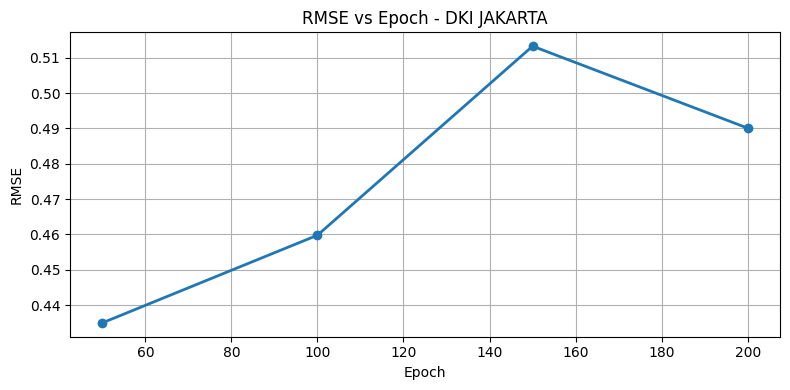

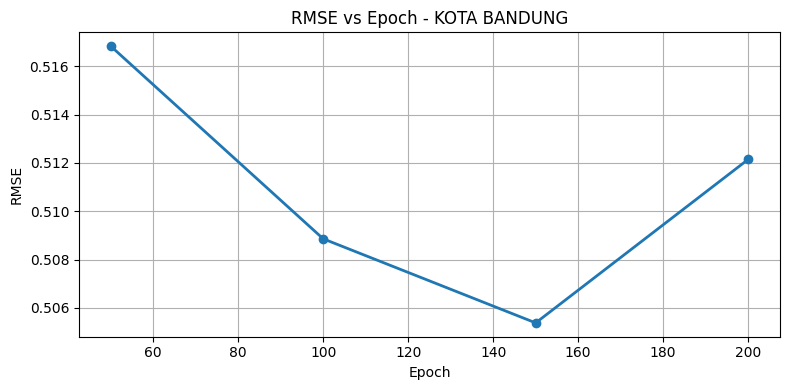

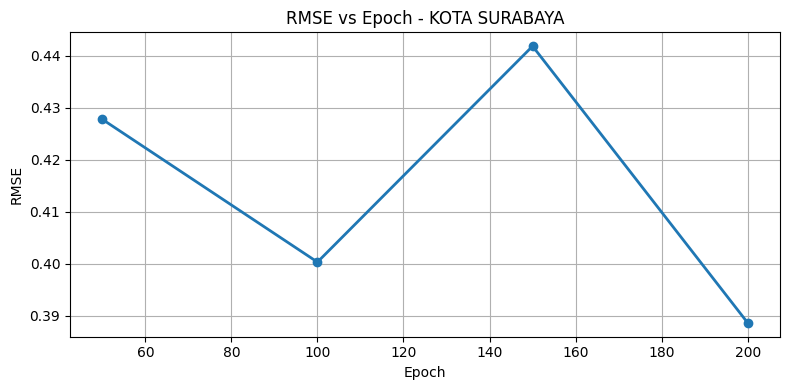

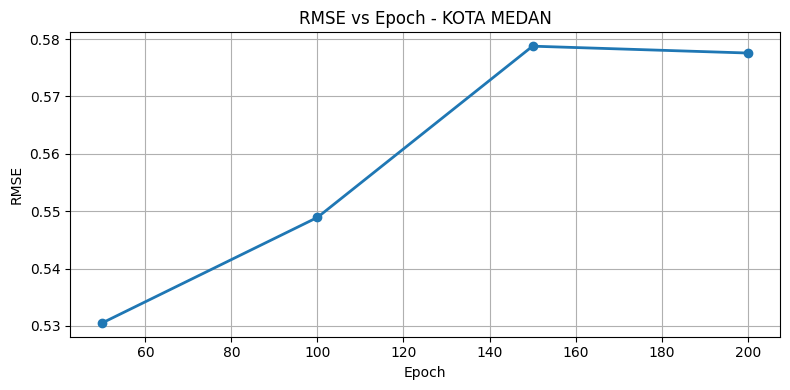

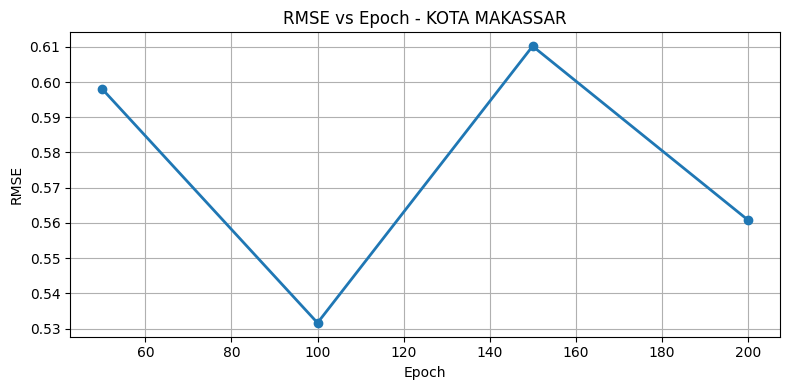

In [ ]:
# ==========================================================
# VISUALISASI RMSE SETIAP EPOCH
# ==========================================================

for city in CITIES:

    plt.figure(figsize=(8,4))

    temp = result_D[result_D["City"] == city]

    plt.plot(
        temp["Epoch"],
        temp["RMSE"],
        marker="o",
        linewidth=2
    )

    plt.title(f"RMSE vs Epoch - {city}")

    plt.xlabel("Epoch")

    plt.ylabel("RMSE")

    plt.grid(True)

    plt.tight_layout()

    plt.show()

In [ ]:
# ==========================================================
# EXPERIMENT E : OPTIMASI BATCH SIZE
# ==========================================================

BATCH_GRID = [

    8,

    16,

    32,

    64

]

experiment_E = []

In [ ]:
# ==========================================================
# MENGAMBIL BEST EPOCH DARI EXPERIMENT D
# ==========================================================

best_epoch_dict = dict(zip(
    best_epoch["City"],
    best_epoch["Epoch"]
))

best_epoch_dict

{'DKI JAKARTA': 50,
 'KOTA BANDUNG': 150,
 'KOTA MAKASSAR': 100,
 'KOTA MEDAN': 50,
 'KOTA SURABAYA': 200}

In [ ]:
# ==========================================================
# EXPERIMENT E : LOOP OPTIMASI BATCH SIZE
# ==========================================================

for city in CITIES:

    print("="*70)
    print(f"KOTA : {city}")
    print("="*70)

    # -----------------------------------
    # Ambil Data Kota
    # -----------------------------------
    city_data = df[df["Kota"] == city].copy()

    # -----------------------------------
    # Scaling
    # -----------------------------------
    city_data, scaler_inflasi, scaler_umr = scale_data(city_data)

    # -----------------------------------
    # Hyperparameter Terbaik
    # -----------------------------------
    lag = best_lag_dict[city]
    units = best_units_dict[city]
    lr = best_lr_dict[city]
    epoch = best_epoch_dict[city]

    print(f"Best Lag           : {lag}")
    print(f"Best Units         : {units}")
    print(f"Best Learning Rate : {lr}")
    print(f"Best Epoch         : {epoch}")

    # -----------------------------------
    # Sequence
    # -----------------------------------
    X, y = create_sequences(
        city_data,
        lag=lag
    )

    X_train, X_test, y_train, y_test = split_data(X, y)

    # =====================================================
    # Loop Batch Size
    # =====================================================

    for batch in BATCH_GRID:

        print(f"\nBatch Size : {batch}")

        clear_session()

        model = build_model(

            input_shape=(X_train.shape[1], X_train.shape[2]),

            units=units,

            learning_rate=lr

        )

        history = train_model(

            model,

            X_train,
            y_train,

            X_test,
            y_test,

            epochs=epoch,

            batch_size=batch

        )

        y_actual, y_pred = predict_model(

            model,

            X_test,

            y_test,

            scaler_inflasi

        )

        metrics = evaluate_model(

            y_actual,

            y_pred

        )

        experiment_E.append({

            "City": city,

            "Lag": lag,

            "Units": str(units),

            "Learning Rate": lr,

            "Epoch": epoch,

            "Batch Size": batch,

            **metrics

        })

        print(
            f"RMSE = {metrics['RMSE']:.4f} | "
            f"MAE = {metrics['MAE']:.4f}"
        )

KOTA : DKI JAKARTA
Best Lag           : 3
Best Units         : (128, 64, 32)
Best Learning Rate : 0.01
Best Epoch         : 50

Batch Size : 8
Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - loss: 1.1352 - mae: 0.6414 - val_loss: 0.4359 - val_mae: 0.4559
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.1512 - mae: 0.6488 - val_loss: 0.5221 - val_mae: 0.5229
Epoch 3/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1266 - mae: 0.6365 - val_loss: 0.5164 - val_mae: 0.5121
Epoch 4/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.1125 - mae: 0.6103 - val_loss: 0.4394 - val_mae: 0.4159
Epoch 5/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.1096 - mae: 0.6185 - val_loss: 0.4070 - val_mae: 0.4325
Epoch 6/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1.0656 - mae: 0.5883 - val_loss: 0.4458 - val_mae: 0.4532
Epoch 7/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.0737 - mae: 0.6234 - val_loss: 0.4067 - val_mae: 0.4201
Epoch 8/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
# ==========================================================
# HASIL EXPERIMENT E
# ==========================================================

result_E = pd.DataFrame(experiment_E)

display(result_E)

result_E.to_csv(
    "experiment_E_batch_size.csv",
    index=False
)

,City,Lag,Units,Learning Rate,Epoch,Batch Size,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,8,0.201587,0.448984,0.275334,1.158405,115.840469
1,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,16,0.186593,0.431964,0.271278,1.079808,107.980795
2,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,32,0.206383,0.454294,0.290084,1.255779,125.577889
3,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,64,0.186415,0.431758,0.269770,1.143901,114.390066
4,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,8,0.285303,0.534137,0.340390,1.074287,107.428740
5,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,16,0.283233,0.532196,0.343696,1.165802,116.580225
6,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,32,0.257448,0.507393,0.319568,1.058488,105.848752
7,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,64,0.255498,0.505468,0.316153,1.030007,103.000681
8,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,200,8,0.160254,0.400318,0.294448,1.002930,100.292974
9,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,200,16,0.181001,0.425442,0.318217,1.208605,120.860478


In [ ]:
# ==========================================================
# BEST BATCH SIZE SETIAP KOTA
# ==========================================================

best_batch = (

    result_E

    .sort_values("RMSE")

    .groupby("City")

    .first()

    .reset_index()

)

display(best_batch)

,City,Lag,Units,Learning Rate,Epoch,Batch Size,MSE,RMSE,MAE,sMAPE,sMAPE (%)
0,DKI JAKARTA,3,"(128, 64, 32)",0.0100,50,64,0.186415,0.431758,0.269770,1.143901,114.390066
1,KOTA BANDUNG,3,"(256, 128, 64)",0.0001,150,64,0.255498,0.505468,0.316153,1.030007,103.000681
2,KOTA MAKASSAR,3,"(256, 128, 64)",0.0010,100,32,0.286455,0.535215,0.372291,1.329513,132.951326
3,KOTA MEDAN,3,"(64, 32, 16)",0.0010,50,32,0.287954,0.536613,0.420849,1.379998,137.999775
4,KOTA SURABAYA,6,"(512, 256, 128)",0.0100,200,64,0.160211,0.400264,0.294488,1.012724,101.272361


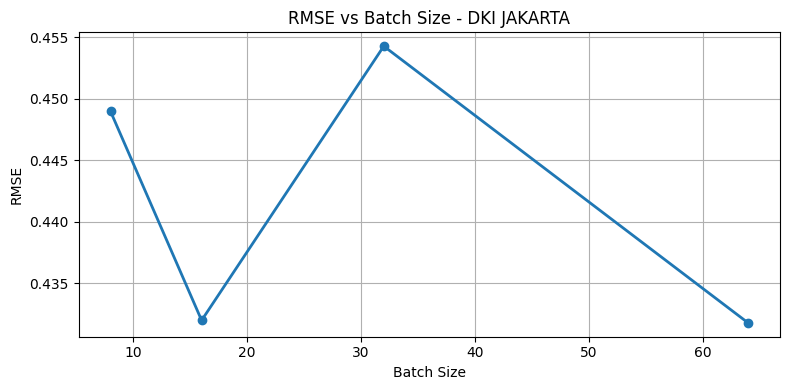

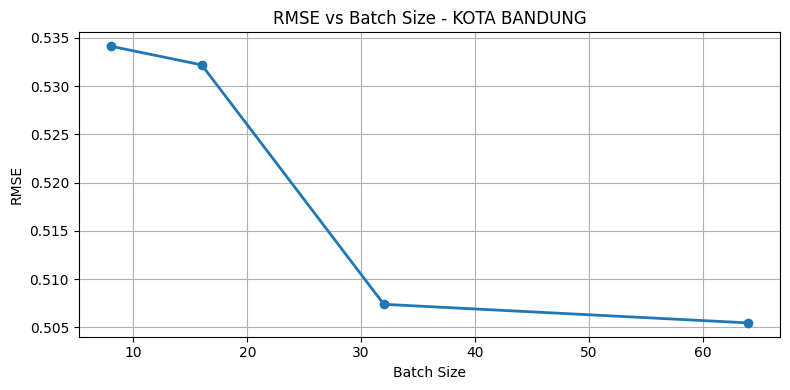

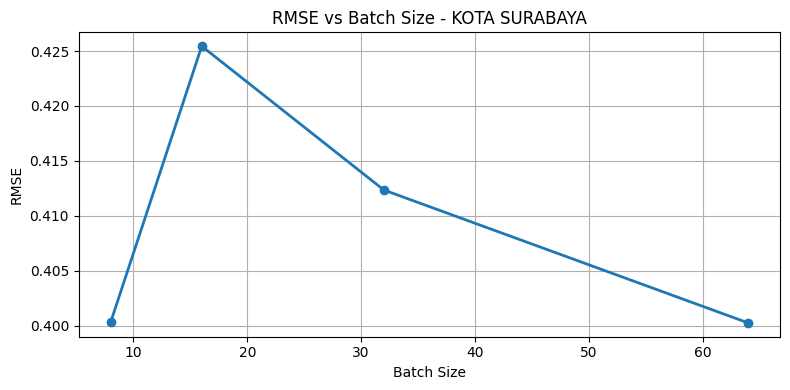

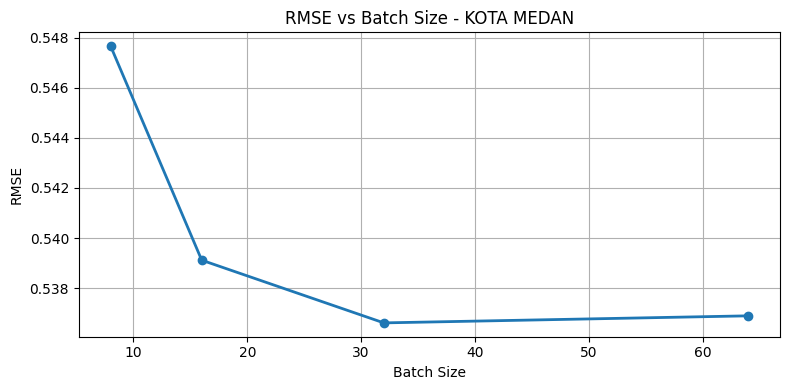

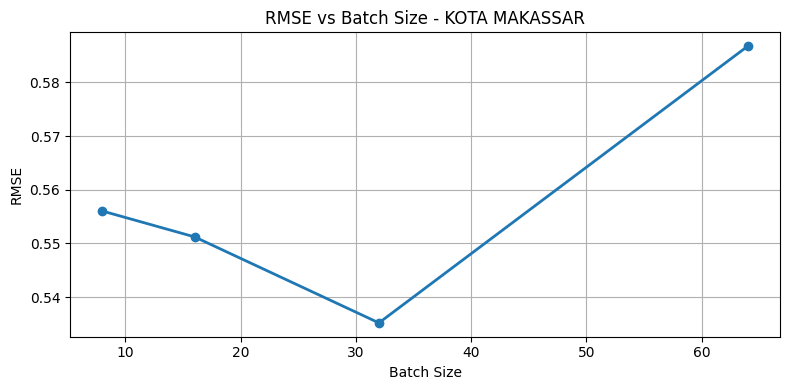

In [ ]:
# ==========================================================
# VISUALISASI RMSE SETIAP BATCH SIZE
# ==========================================================

for city in CITIES:

    plt.figure(figsize=(8,4))

    temp = result_E[result_E["City"] == city]

    plt.plot(
        temp["Batch Size"],
        temp["RMSE"],
        marker="o",
        linewidth=2
    )

    plt.title(f"RMSE vs Batch Size - {city}")

    plt.xlabel("Batch Size")

    plt.ylabel("RMSE")

    plt.grid(True)

    plt.tight_layout()

    plt.show()